# Lab8｜MNIST 手寫數字辨識
學號 `n97141132` · TensorFlow / Keras

在 Google Colab 上傳這份 notebook，選擇「執行階段 → 全部執行」。CPU 可執行，若提供 GPU，CNN 訓練通常更快。最後到左側「檔案」下載 `lab8_output/mnist_model.tflite` 及 `lab8_output/experiment_results.json`。

依《Lab8.pptx》第 35–38、51 頁重建 Sigmoid + SGD；比較相同寬度的 ReLU + Adam、加寬 MLP 和小型 CNN。以改進 MLP 作為 Raspberry Pi 交付模型，維持講義的輸入與輸出規格。

此 notebook 所保留的執行結果來自 Apple Silicon Mac 的 CPU。重新執行可能因裝置與套件版本略有差異。

**本次實測**　講義基準重跑 81.73%，改進 MLP 98.37%（+16.64 個百分點），小型 CNN 99.02%。交付的 MLP 模型轉成 TFLite 後，逐張測試仍為 98.37%。

## 1. 載入資料並固定切分
使用 [Keras MNIST](https://keras.io/api/datasets/mnist/) 的原始順序。前 48,000 張用來訓練，最後 12,000 張用來驗證，對應講義的 `validation_split=0.2`。官方測試集有 10,000 張，訓練及驗證完成後才使用。像素轉為 float32 並除以 255，分類標籤採講義的 one-hot 編碼。

In [1]:
import hashlib
import json
import platform
import sys
from datetime import datetime
from pathlib import Path
from time import perf_counter
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 1234
INPUT_SHAPE = (28, 28, 1)
OUTPUT = Path("lab8_output")
OUTPUT.mkdir(exist_ok=True)

keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
environment = {
    "started_at_taipei": datetime.now(ZoneInfo("Asia/Taipei")).isoformat(timespec="seconds"),
    "system": platform.system(),
    "machine": platform.machine(),
    "python": platform.python_version(),
    "tensorflow": tf.__version__,
    "keras": getattr(keras, "__version__", tf.__version__),
    "numpy": np.__version__,
    "compute": "GPU" if tf.config.list_physical_devices("GPU") else "CPU",
}
print(json.dumps(environment, indent=2))

(train_raw, train_labels), (test_raw, test_labels) = keras.datasets.mnist.load_data()
assert train_raw.shape == (60000, 28, 28)
assert test_raw.shape == (10000, 28, 28)
train_images = train_raw[..., None].astype(np.float32) / 255.0
train_one_hot = keras.utils.to_categorical(train_labels, num_classes=10)
split_at = 48000
x_train, x_val = train_images[:split_at], train_images[split_at:]
y_train, y_val = train_one_hot[:split_at], train_one_hot[split_at:]
print(f"Train: {len(x_train):,} | Validation: {len(x_val):,} | Test: {len(test_raw):,}")

{
  "started_at_taipei": "2026-11-23T19:51:07+08:00",
  "system": "Darwin",
  "machine": "arm64",
  "python": "3.9.20",
  "tensorflow": "2.20.0",
  "keras": "3.10.0",
  "numpy": "1.26.4",
  "compute": "CPU"
}


Train: 48,000 | Validation: 12,000 | Test: 10,000


## 2. 建立四種模型
各模型尾端使用 10 類 Softmax 和 categorical crossentropy。兩個單層 MLP 共用層寬、初始化、批次大小與訓練輪數，分別測試兩組 activation／optimizer 設定。加寬 MLP 採兩層 ReLU 和 Dropout 後再分類。CNN 用卷積與池化擷取局部筆畫特徵。

In [2]:
def single_layer_mlp(activation):
    return keras.Sequential([
        keras.Input(shape=INPUT_SHAPE),
        layers.Flatten(),
        layers.Dense(32, activation=activation, kernel_initializer="random_uniform"),
        layers.Dense(10, activation="softmax", kernel_initializer="normal"),
    ])


def improved_mlp():
    return keras.Sequential([
        keras.Input(shape=INPUT_SHAPE),
        layers.Flatten(),
        layers.Dense(256, activation="relu", kernel_initializer="he_normal"),
        layers.Dropout(0.20),
        layers.Dense(128, activation="relu", kernel_initializer="he_normal"),
        layers.Dropout(0.15),
        layers.Dense(10, activation="softmax"),
    ])


def small_cnn():
    return keras.Sequential([
        keras.Input(shape=INPUT_SHAPE),
        layers.Conv2D(24, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(48, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dropout(0.30),
        layers.Dense(10, activation="softmax"),
    ])


experiments = [
    ("Sigmoid + SGD", lambda: single_layer_mlp("sigmoid"),
     lambda: keras.optimizers.SGD(learning_rate=0.01), 20, 200, False),
    ("ReLU + Adam (32)", lambda: single_layer_mlp("relu"),
     lambda: keras.optimizers.Adam(learning_rate=0.001), 20, 200, False),
    ("Improved MLP", improved_mlp,
     lambda: keras.optimizers.Adam(learning_rate=0.001), 24, 128, True),
    ("Small CNN", small_cnn,
     lambda: keras.optimizers.Adam(learning_rate=0.001), 15, 128, True),
]

## 3. 訓練與選擇權重
兩個單層模型使用最後一輪權重。改進 MLP 與 CNN 在驗證損失停滯時降低學習率，並以驗證準確率最高的一輪權重進入測試。每組重新設定相同種子。

In [3]:
models = {}
results = {}
histories = {}

for name, build_model, make_optimizer, epochs, batch_size, select_best in experiments:
    keras.utils.set_random_seed(SEED)
    model = build_model()
    optimizer = make_optimizer()
    initial_lr = float(optimizer.learning_rate.numpy())
    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"],
        jit_compile=False,
    )
    callbacks = []
    if select_best:
        checkpoint = OUTPUT / ("best_" + name.lower().replace(" ", "_") + ".weights.h5")
        callbacks = [
            keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss", factor=0.5, patience=3, min_lr=0.00005
            ),
            keras.callbacks.ModelCheckpoint(
                checkpoint, monitor="val_accuracy", mode="max",
                save_best_only=True, save_weights_only=True,
            ),
        ]

    print(f"\n{name} | params={model.count_params():,} | epochs={epochs} | batch={batch_size}",
          flush=True)
    start = perf_counter()
    history = model.fit(
        x_train, y_train, validation_data=(x_val, y_val),
        epochs=epochs, batch_size=batch_size, callbacks=callbacks, verbose=2,
    ).history
    train_seconds = perf_counter() - start
    epoch_index = int(np.argmax(history["val_accuracy"])) if select_best else epochs - 1
    if select_best:
        model.load_weights(checkpoint)

    models[name] = model
    histories[name] = history
    results[name] = {
        "parameters": model.count_params(),
        "optimizer": optimizer.__class__.__name__,
        "initial_learning_rate": initial_lr,
        "batch_size": batch_size,
        "trained_epochs": epochs,
        "evaluated_epoch": epoch_index + 1,
        "validation_accuracy": history["val_accuracy"][epoch_index],
        "training_accuracy": history["accuracy"][epoch_index],
        "training_seconds": round(train_seconds, 2),
    }


Sigmoid + SGD | params=25,450 | epochs=20 | batch=200


Epoch 1/20


240/240 - 1s - 3ms/step - accuracy: 0.1033 - loss: 2.2945 - val_accuracy: 0.1060 - val_loss: 2.2847


Epoch 2/20


240/240 - 0s - 1ms/step - accuracy: 0.1143 - loss: 2.2738 - val_accuracy: 0.1092 - val_loss: 2.2630


Epoch 3/20


... (152 outputs left out)

Epoch 14/15


375/375 - 6s - 17ms/step - accuracy: 0.9893 - loss: 0.0319 - val_accuracy: 0.9881 - val_loss: 0.0419 - learning_rate: 0.0010


Epoch 15/15


375/375 - 7s - 19ms/step - accuracy: 0.9904 - loss: 0.0295 - val_accuracy: 0.9892 - val_loss: 0.0404 - learning_rate: 0.0010


## 4. 用官方測試集評估
以 10,000 張測試影像的正確分類數除以總張數。比較講義約 82% 與本次重跑 baseline 的百分點差異。

In [4]:
x_test = test_raw[..., None].astype(np.float32) / 255.0
test_predictions = {}
for name, model in models.items():
    prediction = model.predict(x_test, batch_size=256, verbose=0).argmax(axis=1)
    test_predictions[name] = prediction
    correct = int(np.count_nonzero(prediction == test_labels))
    results[name].update(test_correct=correct, test_accuracy=correct / len(test_labels))

print(f"{'Model':<20} {'Epoch':>5} {'Val acc':>9} {'Correct/total':>15} {'Test acc':>9}")
for name, row in results.items():
    print(f"{name:<20} {row['evaluated_epoch']:>5} {row['validation_accuracy']:>9.2%} "
          f"{row['test_correct']:>8,}/{len(test_labels):<6,} {row['test_accuracy']:>9.2%}")

mlp_accuracy = results["Improved MLP"]["test_accuracy"]
baseline_accuracy = results["Sigmoid + SGD"]["test_accuracy"]
print(f"Improved MLP vs slide baseline (~82%): ~{100*(mlp_accuracy - 0.82):+.2f} pp")
print(f"Improved MLP vs rerun baseline: {100*(mlp_accuracy - baseline_accuracy):+.2f} pp")

Model                Epoch   Val acc   Correct/total  Test acc
Sigmoid + SGD           20    82.16%    8,173/10,000    81.73%
ReLU + Adam (32)        20    96.13%    9,637/10,000    96.37%
Improved MLP            21    98.29%    9,837/10,000    98.37%
Small CNN               15    98.92%    9,902/10,000    99.02%
Improved MLP vs slide baseline (~82%): ~+16.37 pp
Improved MLP vs rerun baseline: +16.64 pp


### 驗證曲線與改進 MLP 混淆矩陣
曲線追蹤訓練過程。混淆矩陣以真實標籤為列、預測標籤為欄，色階與數字分別表達每格占該類別的比例與件數。

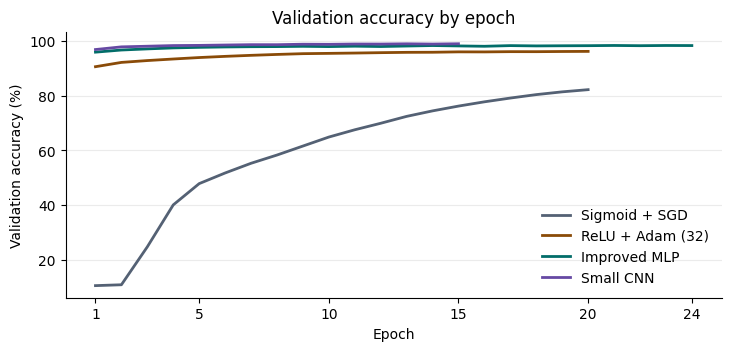

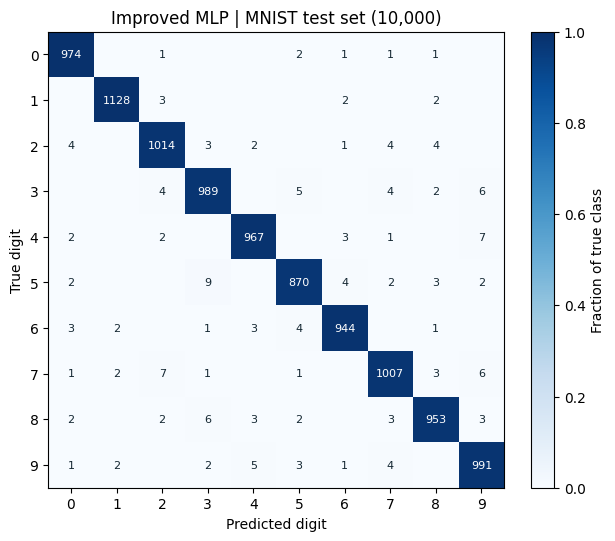

In [5]:
colors = ["#546174", "#8a4b08", "#026d69", "#6649a3"]
fig, ax = plt.subplots(figsize=(7.2, 3.4), layout="constrained")
for (name, history), color in zip(histories.items(), colors):
    values = np.array(history["val_accuracy"]) * 100
    ax.plot(np.arange(1, len(values) + 1), values, label=name, color=color, linewidth=2)
ax.set(xlabel="Epoch", ylabel="Validation accuracy (%)", title="Validation accuracy by epoch")
ax.set_xticks([1, 5, 10, 15, 20, 24])
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", frameon=False)
fig.savefig(OUTPUT / "validation_accuracy.png", dpi=180)
plt.show()

matrix = tf.math.confusion_matrix(test_labels, test_predictions["Improved MLP"], num_classes=10).numpy()
assert matrix.sum() == 10000
assert int(matrix.trace()) == results["Improved MLP"]["test_correct"]
rates = matrix / matrix.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.5, 5.3), layout="constrained")
heatmap = ax.imshow(rates, cmap="Blues", vmin=0, vmax=1)
for true, predicted in np.argwhere(matrix > 0):
    ax.text(predicted, true, str(matrix[true, predicted]), ha="center", va="center",
            color="white" if rates[true, predicted] > 0.5 else "#132631", fontsize=8)
ax.set(xticks=range(10), yticks=range(10), xlabel="Predicted digit", ylabel="True digit",
       title="Improved MLP | MNIST test set (10,000)")
fig.colorbar(heatmap, ax=ax, label="Fraction of true class")
plt.show()

## 5. 匯出並逐張驗證 TFLite
匯出改進 MLP，權重採 FP16 儲存以降低檔案大小。輸入是 `float32 [1, 28, 28, 1]`（黑底白字，範圍 0–1），輸出是 `float32 [1, 10]` 的 Softmax 分數。限定使用 TFLite 內建運算。以單張推論的方式重新測試完整測試集，與 Keras 的分類結果比較。

In [6]:
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2

keras_model = models["Improved MLP"]

@tf.function(input_signature=[tf.TensorSpec([None, *INPUT_SHAPE], tf.float32, name="images")])
def serve(images):
    return keras_model(images, training=False)

# Freeze trained weights into constants before conversion so the LiteRT file is self-contained.
frozen = convert_variables_to_constants_v2(serve.get_concrete_function())
converter = tf.lite.TFLiteConverter.from_concrete_functions([frozen])
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]
tflite_bytes = converter.convert()

# 優先使用課堂部署的 LiteRT，只有本機未安裝時才使用 TensorFlow 內的 interpreter。
try:
    from ai_edge_litert.interpreter import Interpreter
    from importlib.metadata import version
    interpreter_name = f"ai-edge-litert {version('ai-edge-litert')}"
except ImportError:
    Interpreter = tf.lite.Interpreter
    interpreter_name = f"TensorFlow Lite {tf.__version__}"

interpreter = Interpreter(model_content=tflite_bytes, num_threads=1)
interpreter.allocate_tensors()
input_spec, = interpreter.get_input_details()
output_spec, = interpreter.get_output_details()
assert tuple(input_spec["shape"]) == (1, *INPUT_SHAPE) and input_spec["dtype"] == np.float32
assert tuple(output_spec["shape"]) == (1, 10) and output_spec["dtype"] == np.float32

lite_predictions = np.empty(len(test_labels), dtype=np.uint8)
for index, image in enumerate(x_test):
    interpreter.set_tensor(input_spec["index"], image[None, ...])
    interpreter.invoke()
    output = interpreter.get_tensor(output_spec["index"])
    if not np.isfinite(output).all() or not np.isclose(output.sum(), 1.0, atol=1e-4):
        raise ValueError(f"Invalid Softmax output at test image {index}")
    lite_predictions[index] = output.argmax()

lite_correct = int(np.count_nonzero(lite_predictions == test_labels))
agreement = int(np.count_nonzero(lite_predictions == test_predictions["Improved MLP"]))
if agreement / len(test_labels) < 0.99 or abs(lite_correct / len(test_labels) - mlp_accuracy) > 0.005:
    raise ValueError("Exported model does not agree with the trained Keras model.")
model_path = OUTPUT / "mnist_model.tflite"
model_path.write_bytes(tflite_bytes)
deployment = {
    "model": "Improved MLP",
    "format": "FP16 weights, FP32 input and output",
    "interpreter": interpreter_name,
    "test_correct": lite_correct,
    "test_accuracy": lite_correct / len(test_labels),
    "matches_keras": agreement,
    "bytes": len(tflite_bytes),
    "sha256": hashlib.sha256(tflite_bytes).hexdigest(),
    "input_shape": input_spec["shape"].tolist(),
    "output_shape": output_spec["shape"].tolist(),
}
print(json.dumps(deployment, indent=2))

evidence = {
    "environment": environment,
    "seed": SEED,
    "dataset": {"train": len(x_train), "validation": len(x_val), "test": len(test_labels)},
    "lesson_baseline_approx_accuracy": 0.82,
    "results": results,
    "histories": histories,
    "improved_mlp_confusion_matrix": matrix.tolist(),
    "deployment": deployment,
}
evidence_path = OUTPUT / "experiment_results.json"
evidence_path.write_text(json.dumps(evidence, indent=2) + "\n", encoding="utf-8")
print(f"Saved {model_path} and {evidence_path}")

{
  "model": "Improved MLP",
  "format": "FP16 weights, FP32 input and output",
  "interpreter": "TensorFlow Lite 2.20.0",
  "test_correct": 9837,
  "test_accuracy": 0.9837,
  "matches_keras": 10000,
  "bytes": 473236,
  "sha256": "69ea010fa17bf8af3e7d3e64e6a8b3735ea09a69e8d3449003a4053d7e0a05ad",
  "input_shape": [
    1,
    28,
    28,
    1
  ],
  "output_shape": [
    1,
    10
  ]
}
Saved lab8_output/mnist_model.tflite and lab8_output/experiment_results.json


### Raspberry Pi 驗證

依講義將匯出的 `mnist_model.tflite` 和 Moodle 的 `predict.py`、手寫數字 `image.jpg` 放在同一資料夾，執行 `python predict.py`。原版程式產生 `image_processed.png`，將 Pi 上產生的結果圖複製至 `Lab8 Homework/Lab8_n97141132.png`。

本次在 Raspberry Pi 4 辨識手寫數字 4，預測為 4，終端機顯示的信心分數為 95.65%。提交圖直接取自 Pi 的原版程式輸出。Pi 上的模型檔與本次匯出模型的 SHA-256 一致。